In [28]:
import pandas as pd
import pickle
import re
import numpy as np
import matplotlib.pyplot as plt

In [29]:
with open ("/srv/data/enemy-christ/large-data/grouped_df.pkl", "rb") as f:
    grouped = pickle.load(f)

In [30]:
# filter out gnt
#grouped = grouped[~grouped["sentence_id"].str.startswith("lagt_tlg0031")]

In [58]:
grouped_polemical = pd.read_parquet("../data/large-data/grouped_polemical.parquet")

In [59]:
centuries = [(n, n+99) for n in range(1,600,100)]
centuries

[(1, 100), (101, 200), (201, 300), (301, 400), (401, 500), (501, 600)]

In [60]:
# Ensure numeric, and handle missing bounds (choose sensible defaults)
gb = grouped["not_before"].astype("float64").fillna(-1e9)
ga = grouped["not_after"].astype("float64").fillna( 1e9)

pb = grouped_polemical["not_before"].astype("float64").fillna(-1e9)
pa = grouped_polemical["not_after"].astype("float64").fillna( 1e9)

for a, b in centuries:
    label = f"{a}-{b}"
    # overlap: [start,end] intersects [a,b]  <=>  start <= b  AND  end >= a
    grouped[label] = (gb <= b) & (ga >= a)
    grouped_polemical.loc[:, label] = (pb <= b) & (pa >= a)


In [61]:
grouped.head(5)

,grela_id,sentence_id,sentence_position,sent_text,tokens,author,title,not_before,not_after,provenience,enemy_subcorpus,lemma_sentence,1-100,101-200,201-300,301-400,401-500,501-600
0,lagt_ogl0001.ogl001,lagt_ogl0001.ogl001_0,0,"πρὸς ἣν, ὁ Πινυτὸς ἀντιγράφων, θαυμάζει μὲν κ...","[{'char_end': 5, 'char_start': 1, 'lemma': 'πρ...",Pinytus,De Epistola Pinyti ad Dionysium,101,200,christian,christian_0_300,"[πινυτός, ἀντίγραφον, θαυμάζω, ἀποδέχομαι, διο...",False,True,False,False,False,False
1,lagt_ogl0001.ogl001,lagt_ogl0001.ogl001_2,2,δι᾿ ἧς ἐπιστολῆς καὶ ἡ τοῦ Πινυτοῦ περὶ τὴν πί...,"[{'char_end': 3, 'char_start': 0, 'lemma': 'δι...",Pinytus,De Epistola Pinyti ad Dionysium,101,200,christian,christian_0_300,"[ἐπιστολή, πινυτός, πίστις, εὐσέβεια, φροντίς,...",False,True,False,False,False,False
2,lagt_ogl0001.ogl001,lagt_ogl0001.ogl001_1,1,ἀντιπαρακαλεῖ δὲ στεῤῥοτέρας ἤδη ποτὲ μεταδιδό...,"[{'char_end': 13, 'char_start': 0, 'lemma': 'ἀ...",Pinytus,De Epistola Pinyti ad Dionysium,101,200,christian,christian_0_300,"[ἀντιπαρακαλέω, σκληρός, μεταδίδωμι, τροφή, τέ...",False,True,False,False,False,False
3,lagt_tlg0004.tlg001,lagt_tlg0004.tlg001_9227,9227,βλάβας ἐξ ἀνθρώπων ἢ διὰ μῖσος ἢ διὰ φθόνον ἢ ...,"[{'char_end': 6, 'char_start': 0, 'lemma': 'βλ...",Diogenes Laertius,Βίοι καὶ γνῶμαι τῶν ἐν φιλοσοφίᾳ εὐδοκιμησάντων,222,235,pagan,pagan_0_300,"[βλάβη, ἄνθρωπος, μῖσος, φθόνος, καταφρόνησις,...",False,False,True,False,False,False
4,lagt_tlg0004.tlg001,lagt_tlg0004.tlg001_9229,9229,πάθεσι μᾶλλον συσχεθήσεσθαι·,"[{'char_end': 6, 'char_start': 0, 'lemma': 'πά...",Diogenes Laertius,Βίοι καὶ γνῶμαι τῶν ἐν φιλοσοφίᾳ εὐδοκιμησάντων,222,235,pagan,pagan_0_300,"[πάθος, συνέχω]",False,False,True,False,False,False


In [62]:
grouped_polemical.head(5)

,grela_id,sentence_id,sentence_position,sent_text,tokens,author,title,not_before,not_after,provenience,...,pred_polemical,sim_row,polemical_cat_pred,polemical_cat_sim_score,1-100,101-200,201-300,301-400,401-500,501-600
0,lagt_tlg0004.tlg001,lagt_tlg0004.tlg001_9314,9314,"εἰ δὲ μωκώμενος, μάταιος ἐν τοῖς οὐκ ἐπιδεχομέ...","[{'char_end': 2, 'char_start': 0, 'lemma': 'εἰ...",Diogenes Laertius,Βίοι καὶ γνῶμαι τῶν ἐν φιλοσοφίᾳ εὐδοκιμησάντων,222,235,pagan,...,1,0,5,0.891564,False,False,True,False,False,False
1,lagt_tlg0004.tlg001,lagt_tlg0004.tlg001_505,505,"ἴσθι γὰρ τὸν ἄνδρα, ὦ ἑταῖρε, δεινότατα ἁψάμεν...","[{'char_end': 4, 'char_start': 0, 'lemma': 'οἶ...",Diogenes Laertius,Βίοι καὶ γνῶμαι τῶν ἐν φιλοσοφίᾳ εὐδοκιμησάντων,222,235,pagan,...,1,1,5,0.889936,False,False,True,False,False,False
2,lagt_tlg0004.tlg001,lagt_tlg0004.tlg001_627,627,"ἀτυχίαν μὴ ὀνειδίζειν, νέμεσιν αἰδούμενον.","[{'char_end': 7, 'char_start': 0, 'lemma': 'ἀτ...",Diogenes Laertius,Βίοι καὶ γνῶμαι τῶν ἐν φιλοσοφίᾳ εὐδοκιμησάντων,222,235,pagan,...,1,2,1,0.882730,False,False,True,False,False,False
3,lagt_tlg0004.tlg001,lagt_tlg0004.tlg001_807,807,χρόνῳ δὴ ὑπ ὀργῆς βαλὼν ὑποβάθρῳ ἢ λακτίσας τὴ...,"[{'char_end': 5, 'char_start': 0, 'lemma': 'χρ...",Diogenes Laertius,Βίοι καὶ γνῶμαι τῶν ἐν φιλοσοφίᾳ εὐδοκιμησάντων,222,235,pagan,...,1,3,5,0.924578,False,False,True,False,False,False
4,lagt_tlg0004.tlg001,lagt_tlg0004.tlg001_897,897,τὸ ἔλαιον μανίας φάρμακον ἔλεγε διὰ τὸ ἀλειφομ...,"[{'char_end': 2, 'char_start': 0, 'lemma': 'ὁ'...",Diogenes Laertius,Βίοι καὶ γνῶμαι τῶν ἐν φιλοσοφίᾳ εὐδοκιμησάντων,222,235,pagan,...,1,4,5,0.906002,False,False,True,False,False,False


In [63]:
class_names_map = {
    -1: "unpolemical",
     1: "heresy/idolatry/etc.",
     2: "hypocrisy/falsehood",
     3: "arrogance/envy",
     4: "moral depravity/excess",
     5: "strife/violence",
     6: "dubious figures/foreignness"
     #7: "general"
}

In [64]:
grouped_polemical.columns

Index(['grela_id', 'sentence_id', 'sentence_position', 'sent_text', 'tokens',
       'author', 'title', 'not_before', 'not_after', 'provenience',
       'enemy_subcorpus', 'lemma_sentence', 'prob_polemical', 'pred_polemical',
       'sim_row', 'polemical_cat_pred', 'polemical_cat_sim_score', '1-100',
       '101-200', '201-300', '301-400', '401-500', '501-600'],
      dtype='object')

In [65]:
(grouped_polemical["polemical_cat_sim_score"]>0.8).sum()

np.int64(91763)

In [66]:
grouped_polemical = grouped_polemical[grouped_polemical["polemical_cat_sim_score"]>0.8].copy()

In [67]:
print(grouped_polemical["enemy_subcorpus"].value_counts())

enemy_subcorpus
pagan_0_300          37560
christian_300_600    22727
christian_0_300      22385
pagan_300_600         9091
Name: count, dtype: int64


In [68]:
import pandas as pd

cats = [1,2,3,4,5,6]

class_names_map = {
    -1: "unpolemical",
     1: "heresy/idolatry/etc.",
     2: "hypocrisy/falsehood",
     3: "arrogance/envy",
     4: "moral depravity/excess",
     5: "strife/violence",
     6: "dubious figures/foreignness"
}

# --- denominators ---
all_totals = grouped["enemy_subcorpus"].value_counts().sort_index()
polem_totals = grouped_polemical["enemy_subcorpus"].value_counts().sort_index()

# --- numerator: counts by (category x enemy_subcorpus) ---
counts = (
    pd.crosstab(
        grouped_polemical["polemical_cat_pred"],
        grouped_polemical["enemy_subcorpus"]
    )
    .reindex(index=cats, fill_value=0)
)

# consistent column order (optional)
counts = counts.reindex(columns=all_totals.index, fill_value=0)

# map category ids -> labels
counts.index = [class_names_map.get(c, f"Category {c}") for c in counts.index]
counts.index.name = "polemical_category"

print("COUNTS (category x enemy_subcorpus)")
display(counts)

# --- frequency as share of ALL sentences in each subcorpus (from grouped) ---
freq_all = counts.div(all_totals, axis=1)
print("FREQUENCY (share of ALL sentences in each subcorpus)")
display(freq_all.style.format("{:.3%}"))

# --- frequency as share of POLEMICAL sentences in each subcorpus (from grouped_polemical) ---
freq_polem = counts.div(polem_totals, axis=1)
print("FREQUENCY (share of POLEMICAL sentences in each subcorpus)")
display(freq_polem.style.format("{:.3%}"))

COUNTS (category x enemy_subcorpus)


enemy_subcorpus,christian_0_300,christian_300_600,pagan_0_300,pagan_300_600
polemical_category,,,,
heresy/idolatry/etc.,10615,8967,5426,1757
hypocrisy/falsehood,2121,1626,3368,1186
arrogance/envy,355,535,1839,516
moral depravity/excess,1950,1119,1943,364
strife/violence,6521,9997,24680,5221
dubious figures/foreignness,823,483,304,47


FREQUENCY (share of ALL sentences in each subcorpus)


enemy_subcorpus,christian_0_300,christian_300_600,pagan_0_300,pagan_300_600
polemical_category,,,,
heresy/idolatry/etc.,8.656%,5.089%,0.995%,1.118%
hypocrisy/falsehood,1.729%,0.923%,0.618%,0.755%
arrogance/envy,0.289%,0.304%,0.337%,0.328%
moral depravity/excess,1.590%,0.635%,0.356%,0.232%
strife/violence,5.317%,5.673%,4.526%,3.322%
dubious figures/foreignness,0.671%,0.274%,0.056%,0.030%


FREQUENCY (share of POLEMICAL sentences in each subcorpus)


enemy_subcorpus,christian_0_300,christian_300_600,pagan_0_300,pagan_300_600
polemical_category,,,,
heresy/idolatry/etc.,47.420%,39.455%,14.446%,19.327%
hypocrisy/falsehood,9.475%,7.154%,8.967%,13.046%
arrogance/envy,1.586%,2.354%,4.896%,5.676%
moral depravity/excess,8.711%,4.924%,5.173%,4.004%
strife/violence,29.131%,43.987%,65.708%,57.430%
dubious figures/foreignness,3.677%,2.125%,0.809%,0.517%


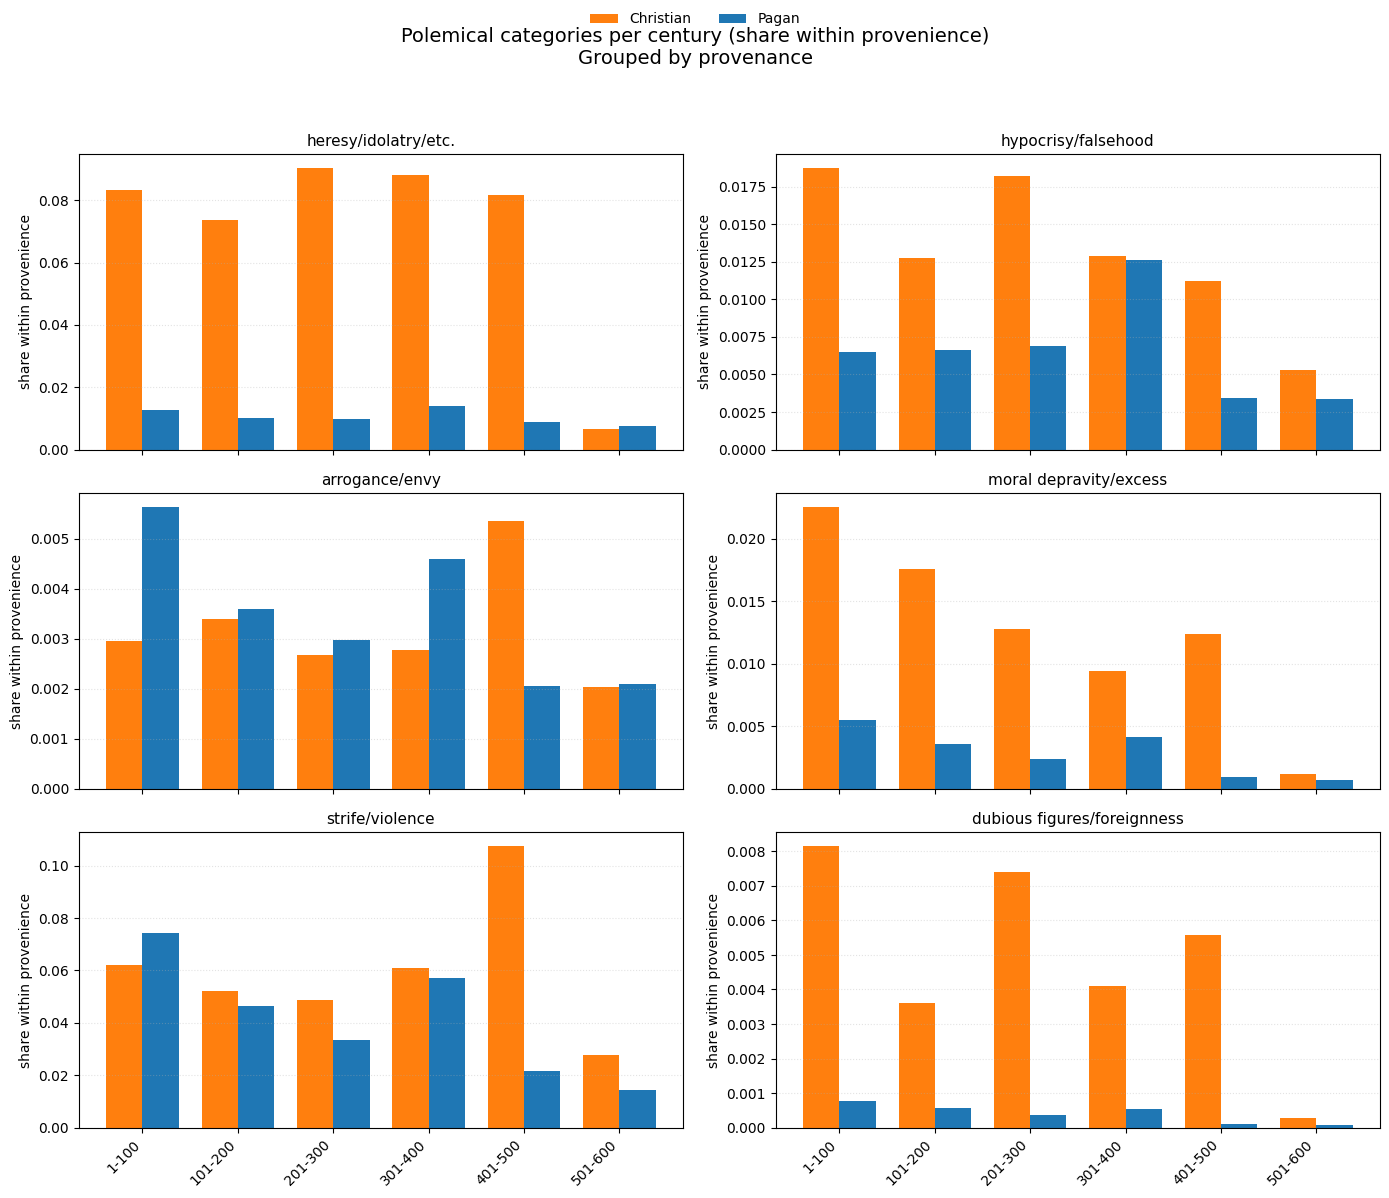

In [69]:
import numpy as np
import matplotlib.pyplot as plt
import re

# ----- columns & sets -----
century_cols = [c for c in grouped.columns if re.fullmatch(r"\d+-\d+", c)]
century_cols = sorted(century_cols, key=lambda s: int(s.split("-")[0]))

cats   = [1,2,3,4,5,6]
provs  = ["christian", "pagan"]
colors = {"pagan": "#1f77b4", "christian": "#ff7f0e"}

mode = "grouped"
normalize_within_prov = True  # shares within provenience per century

# ----- denominator: ALL sentences per century, per provenience (from grouped) -----
prov_col = "lagt_provenience" if "lagt_provenience" in grouped.columns else "provenience"

denom = {}
for prov in provs:
    m = (grouped[prov_col] == prov)
    d = np.array([grouped.loc[m, col].sum() for col in century_cols], dtype=float)
    d[d == 0] = np.nan
    denom[prov] = d

# ----- numerator: counts per cat+prov+century (from grouped_polemical) -----
counts = {}
for cat in cats:
    counts[cat] = {}
    cat_mask = (grouped_polemical["polemical_cat_pred"] == cat)
    for prov in provs:
        prov_mask = (grouped_polemical["provenience"] == prov)
        per_cent = []
        for col in century_cols:
            per_cent.append(int((cat_mask & prov_mask & grouped_polemical[col]).sum()))
        counts[cat][prov] = np.array(per_cent, dtype=float)

# ----- normalize to shares within provenience -----
if normalize_within_prov:
    for cat in cats:
        for prov in provs:
            counts[cat][prov] = counts[cat][prov] / denom[prov]

# ----- plot -----
rows, cols = 3, 2
fig, axes = plt.subplots(rows, cols, figsize=(14, 12), sharex=True)  # no sharey
axes = axes.ravel()

x = np.arange(len(century_cols))
barw = 0.38

for i, cat in enumerate(cats):
    ax = axes[i]

    ax.bar(x - barw/2, counts[cat]["christian"], width=barw, label="Christian", color=colors["christian"])
    ax.bar(x + barw/2, counts[cat]["pagan"],     width=barw, label="Pagan",     color=colors["pagan"])

    ax.set_ylabel("share within provenience" if normalize_within_prov else "count")
    ax.set_title(class_names_map.get(cat, str(cat)), fontsize=11)
    ax.grid(axis="y", linestyle=":", alpha=0.35)
    ax.set_xticks(x, century_cols, rotation=45, ha="right")

# one legend
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=4, frameon=False)

# hide unused panels
for j in range(len(cats), rows*cols):
    axes[j].axis("off")

fig.suptitle(
    "Polemical categories per century (share within provenience)\n"
    f"{mode.capitalize()} by provenance",
    fontsize=14, y=0.98
)
fig.tight_layout(rect=[0,0,1,0.95])
plt.show()

In [70]:
fig.savefig("../figures/grouped-polemical-temporal-grouped.png")

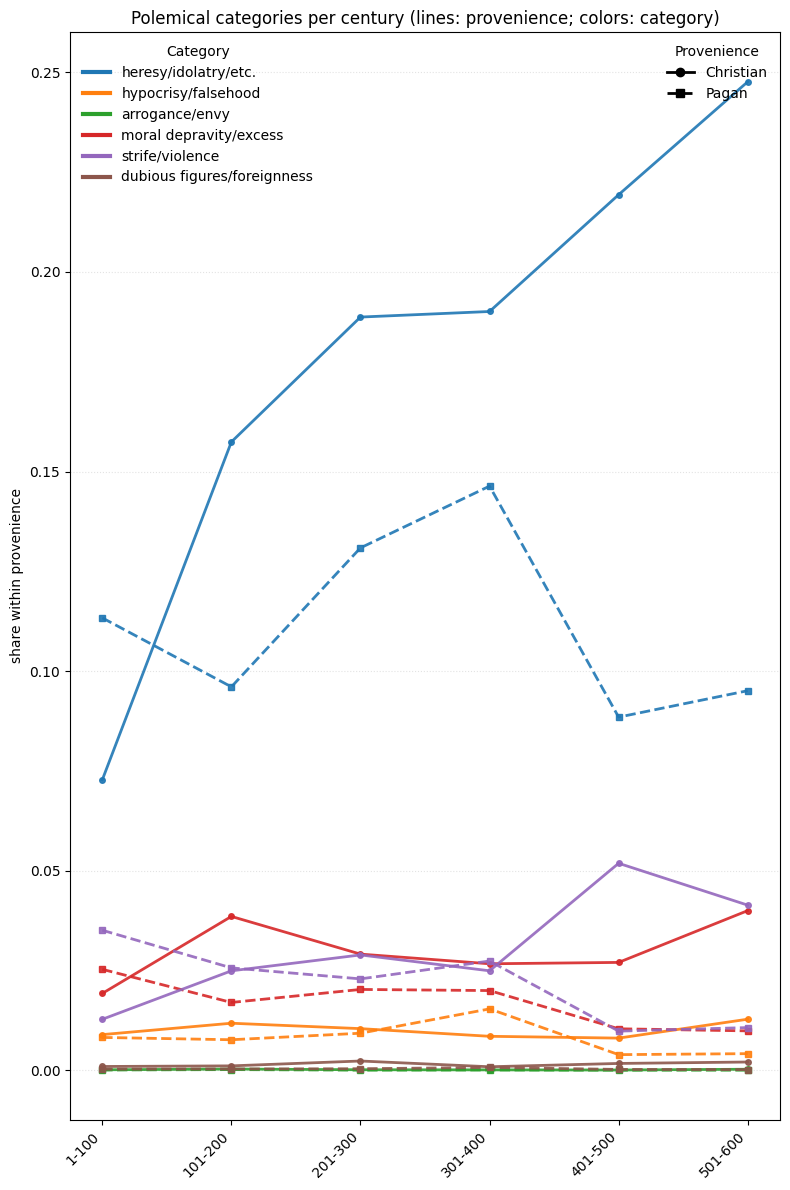

In [27]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

x = np.arange(len(century_cols))

# assign one color per category
cmap = plt.get_cmap("tab10")
cat_colors = {cat: cmap(i) for i, cat in enumerate(cats)}

linestyles = {"christian": "-", "pagan": "--"}
markers    = {"christian": "o", "pagan": "s"}

fig, ax = plt.subplots(figsize=(8, 12))

# plot 2 lines per category (same color; different style)
for cat in cats:
    for prov in provs:
        ax.plot(
            x,
            counts[cat][prov],
            linestyle=linestyles[prov],
            marker=markers[prov],
            linewidth=2,
            markersize=4,
            color=cat_colors[cat],
            alpha=0.9,
        )

ax.set_xticks(x, century_cols, rotation=45, ha="right")
ax.set_ylabel("share within provenience")
ax.set_title("Polemical categories per century (lines: provenience; colors: category)")
ax.grid(axis="y", linestyle=":", alpha=0.35)

# ---- two legends: categories (colors) + provenience (linestyles) ----
cat_handles = [
    Line2D([0], [0], color=cat_colors[cat], lw=3,
           label=class_names_map.get(cat, f"Category {cat}"))
    for cat in cats
]
prov_handles = [
    Line2D([0], [0], color="black", lw=2, linestyle=linestyles[p],
           marker=markers[p], label=p.capitalize())
    for p in provs
]

leg1 = ax.legend(handles=cat_handles, title="Category", loc="upper left", frameon=False)
ax.add_artist(leg1)
ax.legend(handles=prov_handles, title="Provenience", loc="upper right", frameon=False)

plt.tight_layout()
plt.show()

In [ ]:
# century columns you created earlier, e.g. "1-100", "101-200", ...
century_cols = [c for c in grouped_polemical.columns if re.fullmatch(r"\d+-\d+", c)]
century_cols = sorted(century_cols, key=lambda s: int(s.split("-")[0]))  # sort by start year

cats   = [1,2,3,4,5,6]
provs  = ["christian", "pagan"]
colors = {"pagan": "#1f77b4", "christian": "#ff7f0e"}  # tweak as you like

# Settings
mode = "stacked"          # "stacked" or "grouped"
normalize = False         # if True and mode="stacked": stack heights sum to 1 per century

# Precompute counts[cat][prov] -> list per century
counts = {}
for cat in cats:
    counts[cat] = {}
    for prov in provs:
        per_cent = []
        cat_mask  = (grouped_polemical["polemical_cat_pred"] == cat)
        prov_mask = (grouped_polemical["lagt_provenience"] == prov)
        for col in century_cols:
            per_cent.append(int((cat_mask & prov_mask & grouped_polemical[col]).sum()))
        counts[cat][prov] = np.array(per_cent, dtype=float)

# Optional normalization (only makes sense for stacked)
if normalize and mode == "stacked":
    for cat in cats:
        total = counts[cat]["christian"] + counts[cat]["pagan"]
        total[total == 0] = 1.0  # avoid div-by-zero
        counts[cat]["christian"] = counts[cat]["christian"] / total
        counts[cat]["pagan"]     = counts[cat]["pagan"]     / total

# Shared y-limit across plots (use totals if stacked, max per bar if grouped)
if mode == "stacked":
    global_max = max((counts[c]["christian"] + counts[c]["pagan"]).max() for c in cats)
else:
    global_max = max(max(counts[c][p].max() for p in provs) for c in cats)
ylim = (0, (1.0 if (normalize and mode=="stacked") else global_max*1.1) or 1)

# Plot: 4x2 grid (last cell hidden)
rows, cols = 4, 2
fig, axes = plt.subplots(rows, cols, figsize=(14, 12), sharex=True)
axes = axes.ravel()

x = np.arange(len(century_cols))
barw = 0.38  # for grouped

for i, cat in enumerate(cats):
    ax = axes[i]
    if mode == "stacked":
        ax.bar(x, counts[cat]["christian"], label="Christian", color=colors["christian"])
        ax.bar(x, counts[cat]["pagan"], bottom=counts[cat]["christian"], label="Pagan", color=colors["pagan"])
        ax.set_ylabel("share" if normalize else "count")
    else:  # grouped
        ax.bar(x - barw/2, counts[cat]["christian"], width=barw, label="Christian", color=colors["christian"])
        ax.bar(x + barw/2, counts[cat]["pagan"],     width=barw, label="Pagan",     color=colors["pagan"])
        ax.set_ylabel("count")

    ax.set_title(class_names_map.get(cat, str(cat)), fontsize=11)
    #ax.set_ylim(*ylim)
    ax.grid(axis="y", linestyle=":", alpha=0.35)
    ax.set_xticks(x, century_cols, rotation=45, ha="right")

# Legend once
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=4, frameon=False)

# Hide any unused subplot
if len(cats) < rows*cols:
    for j in range(len(cats), rows*cols):
        axes[j].axis("off")

fig.suptitle(
    f"Temporal distribution by predicted polemical category\n"
    f"{'(stacked, normalized)' if (mode=='stacked' and normalize) else '('+mode+')'}",
    fontsize=14, y=0.98
)
fig.tight_layout(rect=[0,0,1,0.95])
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import re

# ----- columns & sets -----
century_cols = [c for c in grouped.columns if re.fullmatch(r"\d+-\d+", c)]
century_cols = sorted(century_cols, key=lambda s: int(s.split("-")[0]))

cats   = [1,2,3,4,5,6]                # add 7 if you want "general"
provs  = ["christian", "pagan"]
colors = {"pagan": "#1f77b4", "christian": "#ff7f0e"}

mode = "stacked"                      # "stacked" or "grouped"
normalize_by_total = True            # << key switch: normalize by ALL sentences per century

# ----- denominator: ALL sentences per century (from grouped) -----
# These columns are booleans; sum() counts rows in that century.
denom = np.array([grouped[col].sum() for col in century_cols], dtype=float)
denom_safe = denom.copy()
denom_safe[denom_safe == 0] = np.nan   # avoid div-by-zero

# ----- numerator: counts per cat+prov+century (from grouped_polemical) -----
counts = {}
for cat in cats:
    counts[cat] = {}
    cat_mask = (grouped_polemical["polemical_cat_pred"] == cat)
    for prov in provs:
        prov_mask = (grouped_polemical["lagt_provenience"] == prov)
        per_cent = []
        for col in century_cols:
            per_cent.append(int((cat_mask & prov_mask & grouped_polemical[col]).sum()))
        counts[cat][prov] = np.array(per_cent, dtype=float)

# ----- optionally convert to shares of ALL sentences in that century -----
if normalize_by_total:
    for cat in cats:
        for prov in provs:
            counts[cat][prov] = counts[cat][prov] / denom_safe  # elementwise; may yield NaN where denom=0

# ----- y-limit -----
if mode == "stacked":
    global_max = np.nanmax([(counts[c]["christian"] + counts[c]["pagan"]).max() for c in cats])
else:
    global_max = np.nanmax([max(counts[c][p].max() for p in provs) for c in cats])
ylim = (0, (global_max if np.isfinite(global_max) else 1) * 1.1)

# ----- plot -----
rows, cols = 3, 2
fig, axes = plt.subplots(rows, cols, figsize=(14, 12), sharex=True)
axes = axes.ravel()

x = np.arange(len(century_cols))
barw = 0.38

for i, cat in enumerate(cats):
    ax = axes[i]

    if mode == "stacked":
        ax.bar(x, counts[cat]["christian"], label="Christian", color=colors["christian"])
        ax.bar(x, counts[cat]["pagan"], bottom=counts[cat]["christian"], label="Pagan", color=colors["pagan"])
        ax.set_ylabel("share of all sentences")
    else:
        ax.bar(x - barw/2, counts[cat]["christian"], width=barw, label="Christian", color=colors["christian"])
        ax.bar(x + barw/2, counts[cat]["pagan"],     width=barw, label="Pagan",     color=colors["pagan"])
        ax.set_ylabel("share of all sentences" if normalize_by_total else "count")

    ax.set_title(class_names_map.get(cat, str(cat)), fontsize=11)
    #ax.set_ylim(*ylim)
    ax.grid(axis="y", linestyle=":", alpha=0.35)
    ax.set_xticks(x, century_cols, rotation=45, ha="right")

# one legend
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=4, frameon=False)

# hide unused panels
for j in range(len(cats), rows*cols):
    axes[j].axis("off")

fig.suptitle(
    "Polemical categories per century (share of all sentences)\n"
    f"{mode.capitalize()} by provenance",
    fontsize=14, y=0.98
)
fig.tight_layout(rect=[0,0,1,0.95])
plt.show()

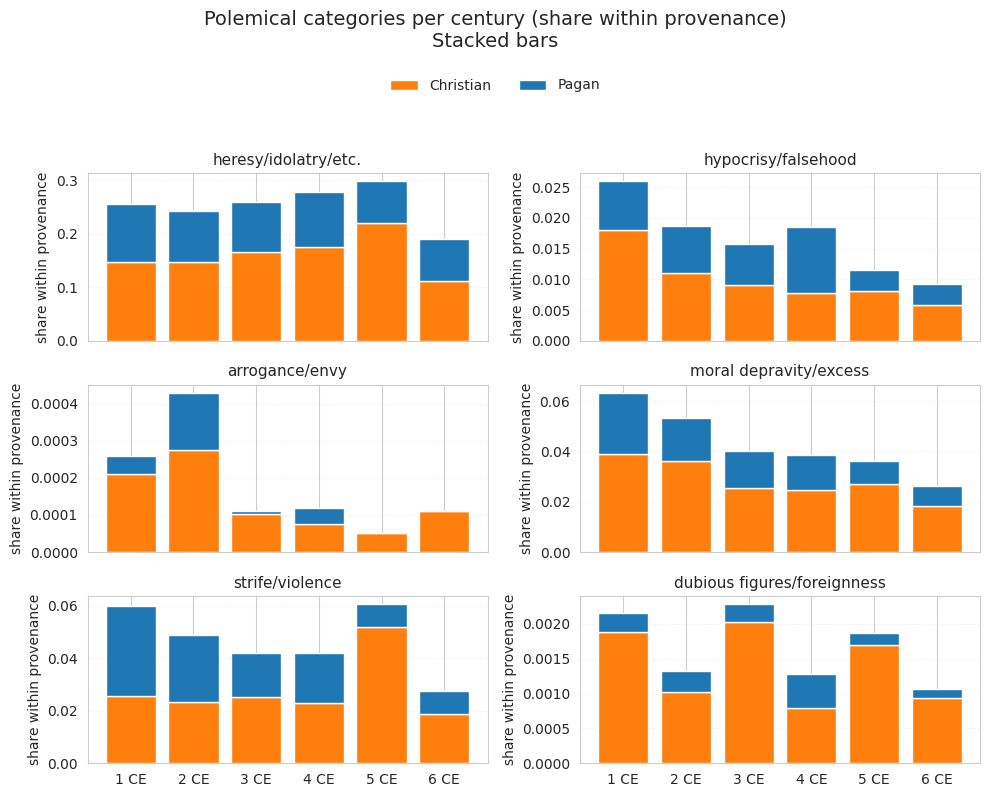

In [61]:
import numpy as np
import re
import matplotlib.pyplot as plt

# ----- columns & sets -----
century_cols = [c for c in grouped.columns if re.fullmatch(r"\d+-\d+", c)]
century_cols = sorted(century_cols, key=lambda s: int(s.split("-")[0]))

cats   = [1,2,3,4,5,6]                 # add 7 if you also want "general"
provs  = ["christian", "pagan"]
colors = {"pagan": "#1f77b4", "christian": "#ff7f0e"}

mode = "stacked"                       # "stacked" or "grouped"
normalize_by_prov_total = True         # << key switch: normalize by total sentences of the SAME provenance per century

# ----- denominators: ALL sentences per provenance & century (from grouped) -----
denom_prov = {}
for prov in provs:
    pm = grouped["lagt_provenience"].eq(prov)
    per_cent = [int((pm & grouped[col]).sum()) for col in century_cols]
    v = np.array(per_cent, dtype=float)
    v[v == 0] = np.nan                   # avoid div-by-zero; will yield NaN where no data
    denom_prov[prov] = v

# ----- numerators: counts per cat+prov+century (from grouped_polemical) -----
counts = {}
for cat in cats:
    counts[cat] = {}
    cat_mask = (grouped_polemical["polemical_cat_pred"] == cat)
    for prov in provs:
        prov_mask = grouped_polemical["lagt_provenience"].eq(prov)
        per_cent = [int((cat_mask & prov_mask & grouped_polemical[col]).sum()) for col in century_cols]
        counts[cat][prov] = np.array(per_cent, dtype=float)

# ----- convert to shares within provenance per century -----
if normalize_by_prov_total:
    for cat in cats:
        for prov in provs:
            counts[cat][prov] = counts[cat][prov] / denom_prov[prov]

# ----- y-limit -----
if mode == "stacked":
    global_max = np.nanmax([(counts[c]["christian"] + counts[c]["pagan"]).max() for c in cats])
else:
    global_max = np.nanmax([max(counts[c][p].max() for p in provs) for c in cats])
ylim = (0, (global_max if np.isfinite(global_max) else 1) * 1.1)

# pretty labels like "1 CE", "2 CE", ...
pretty_century_labels = [f"{int(c.split('-')[0])//100 + 1} CE" for c in century_cols]

# ----- plot -----
rows, cols = 3, 2
fig, axes = plt.subplots(rows, cols, figsize=(10, 8), sharex=True)
axes = axes.ravel()

x = np.arange(len(century_cols))
barw = 0.38

for i, cat in enumerate(cats):
    ax = axes[i]
    if mode == "stacked":
        ax.bar(x, counts[cat]["christian"], label="Christian", color=colors["christian"])
        ax.bar(x, counts[cat]["pagan"], bottom=counts[cat]["christian"], label="Pagan", color=colors["pagan"])
        ax.set_ylabel("share within provenance")
    else:
        ax.bar(x - barw/2, counts[cat]["christian"], width=barw, label="Christian", color=colors["christian"])
        ax.bar(x + barw/2, counts[cat]["pagan"],     width=barw, label="Pagan",     color=colors["pagan"])
        ax.set_ylabel("share within provenance" if normalize_by_prov_total else "count")

    ax.set_title(class_names_map.get(cat, str(cat)), fontsize=11)
    #ax.set_ylim(*ylim)
    ax.grid(axis="y", linestyle=":", alpha=0.35)

    # only put xticks on bottom row
    if i // cols == rows - 1:
        ax.set_xticks(x, pretty_century_labels, rotation=0)
    else:
        ax.set_xticks([])

# one legend (below title)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.92), ncol=4, frameon=False)

fig.suptitle(
    "Polemical categories per century (share within provenance)\n"
    f"{mode.capitalize()} bars",
    fontsize=14, y=0.99
)
fig.tight_layout(rect=[0,0,1,0.90])  # space for legend + title

# hide unused panels (if any)
for j in range(len(cats), rows*cols):
    axes[j].axis("off")

plt.show()

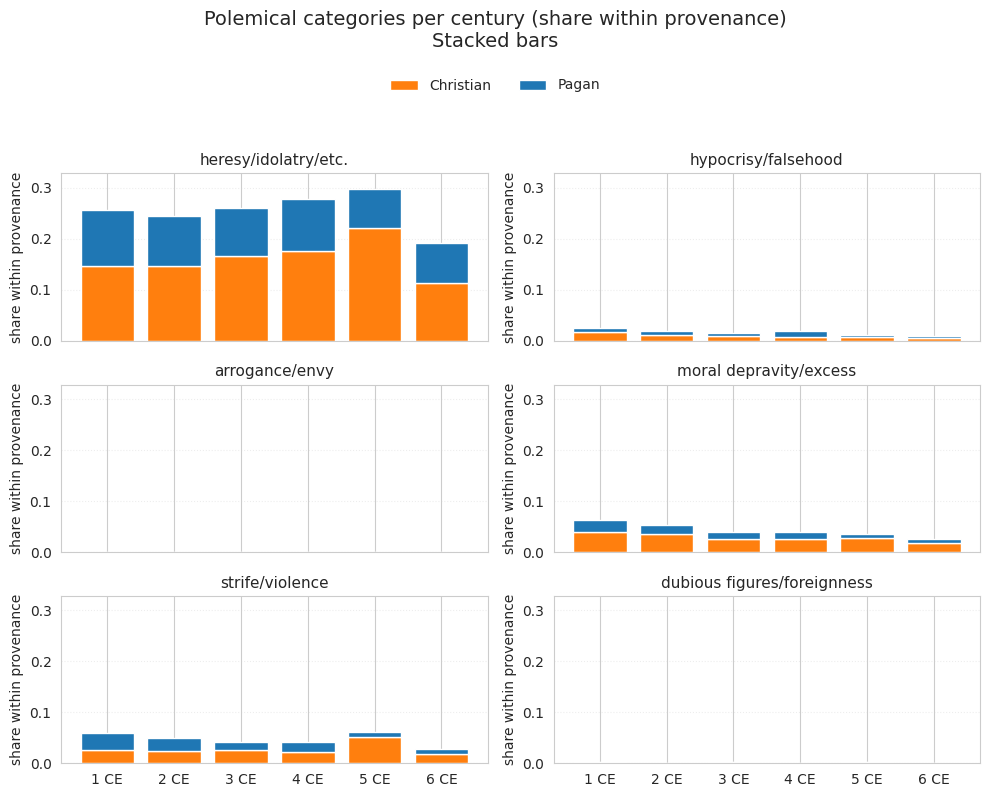

In [62]:
import numpy as np
import re
import matplotlib.pyplot as plt

# ----- pick the base for denominators (IMPORTANT) -----
grouped_base = grouped        # or grouped_filtered if that's your reference elsewhere

# ----- century columns -----
century_cols = [c for c in grouped_base.columns if re.fullmatch(r"\d+-\d+", c)]
century_cols = sorted(century_cols, key=lambda s: int(s.split("-")[0]))

cats   = [1,2,3,4,5,6]
provs  = ["christian", "pagan"]
colors = {"pagan": "#1f77b4", "christian": "#ff7f0e"}

mode = "stacked"
normalize_by_prov_total = True

# ----- denominators: ALL sentences per provenance & century (from grouped_base) -----
denom_prov = {}
for prov in provs:
    pm = grouped_base["lagt_provenience"].eq(prov)
    per_cent = [(pm & grouped_base[col]).sum() for col in century_cols]
    v = np.array(per_cent, dtype=float)
    v[v == 0] = np.nan   # will normalize to NaN; we'll later replace by 0 for plotting
    denom_prov[prov] = v

# (Optional) quick sanity print
# print({prov: denom_prov[prov] for prov in provs})

# ----- numerators: counts per cat+prov+century (from grouped_polemical) -----
counts = {}
for cat in cats:
    counts[cat] = {}
    cat_mask = (grouped_polemical["polemical_cat_pred"] == cat)
    for prov in provs:
        prov_mask = grouped_polemical["lagt_provenience"].eq(prov)
        per_cent = [(cat_mask & prov_mask & grouped_polemical[col]).sum() for col in century_cols]
        counts[cat][prov] = np.array(per_cent, dtype=float)

# ----- normalize within provenance & handle NaNs -----
if normalize_by_prov_total:
    for cat in cats:
        for prov in provs:
            shares = counts[cat][prov] / denom_prov[prov]
            # Replace NaNs (no denominator that century) with 0 for plotting
            shares = np.nan_to_num(shares, nan=0.0, posinf=0.0, neginf=0.0)
            # Clamp tiny float wiggles
            shares = np.clip(shares, 0.0, 1.0)
            counts[cat][prov] = shares

# ----- y-limit -----
if mode == "stacked":
    global_max = max((counts[c]["christian"] + counts[c]["pagan"]).max() for c in cats)
else:
    global_max = max(max(counts[c][p].max() for p in provs) for c in cats)
ylim = (0, (global_max if np.isfinite(global_max) else 1) * 1.1)

# Pretty labels like "1 CE", "2 CE", ...
pretty_century_labels = [f"{int(c.split('-')[0])//100 + 1} CE" for c in century_cols]

# ----- plot -----
rows, cols = 3, 2
fig, axes = plt.subplots(rows, cols, figsize=(10, 8), sharex=True)
axes = axes.ravel()

x = np.arange(len(century_cols))
barw = 0.38

for i, cat in enumerate(cats):
    ax = axes[i]
    if mode == "stacked":
        ax.bar(x, counts[cat]["christian"], label="Christian", color=colors["christian"])
        ax.bar(x, counts[cat]["pagan"], bottom=counts[cat]["christian"], label="Pagan", color=colors["pagan"])
        ax.set_ylabel("share within provenance")
    else:
        ax.bar(x - barw/2, counts[cat]["christian"], width=barw, label="Christian", color=colors["christian"])
        ax.bar(x + barw/2, counts[cat]["pagan"],     width=barw, label="Pagan",     color=colors["pagan"])
        ax.set_ylabel("share within provenance")

    ax.set_title(class_names_map.get(cat, str(cat)), fontsize=11)
    ax.set_ylim(*ylim)
    ax.grid(axis="y", linestyle=":", alpha=0.35)

    # only xticks on bottom row
    if i // cols == rows - 1:
        ax.set_xticks(x, pretty_century_labels, rotation=0)
    else:
        ax.set_xticks([])

# legend below title
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.92), ncol=4, frameon=False)

fig.suptitle(
    "Polemical categories per century (share within provenance)\n"
    f"{mode.capitalize()} bars",
    fontsize=14, y=0.99
)
fig.tight_layout(rect=[0,0,1,0.90])

# hide unused panels (if any)
for j in range(len(cats), rows*cols):
    axes[j].axis("off")

plt.show()

In [59]:
fig.savefig("../figures/grouped-polemical-temporal.png")